# Семинар: Нейронные сети

**Цели семинара:**
1. Понять математику нейрона, увидеть разницу между функциями активации.
2. Сравнить линейную модель и нелинейную (MLP) на 2D-данных.
3. Написать цикл обучения нейросети на PyTorch (от `forward` до `optimizer.step()`).
4. Увидеть, как регуляризация (Dropout) и выбор оптимизатора (SGD vs Adam) влияют на обучение.

In [2]:
%pip install torch torchvision scikit-learn matplotlib numpy -q

Note: you may need to restart the kernel to use updated packages.


In [1]:
%pip install "numpy<2.0" -q

^C
Note: you may need to restart the kernel to use updated packages.


In [ ]:
%pip install --upgrade torch torchvision

   ━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━ 55.6/138.6 MB 268.5 kB/s eta 0:05:10

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_moons, load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(42)
torch.manual_seed(42)

In [5]:
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device = torch.device('cpu')
print(f'Используемое устройство: {device}')

Используемое устройство: cpu


## Часть 1. Функции активации и затухающий градиент
Нарисуем популярные активации и их производные. Обратите внимание, как быстро убывает градиент у Sigmoid/Tanh (проблема *vanishing gradient*).

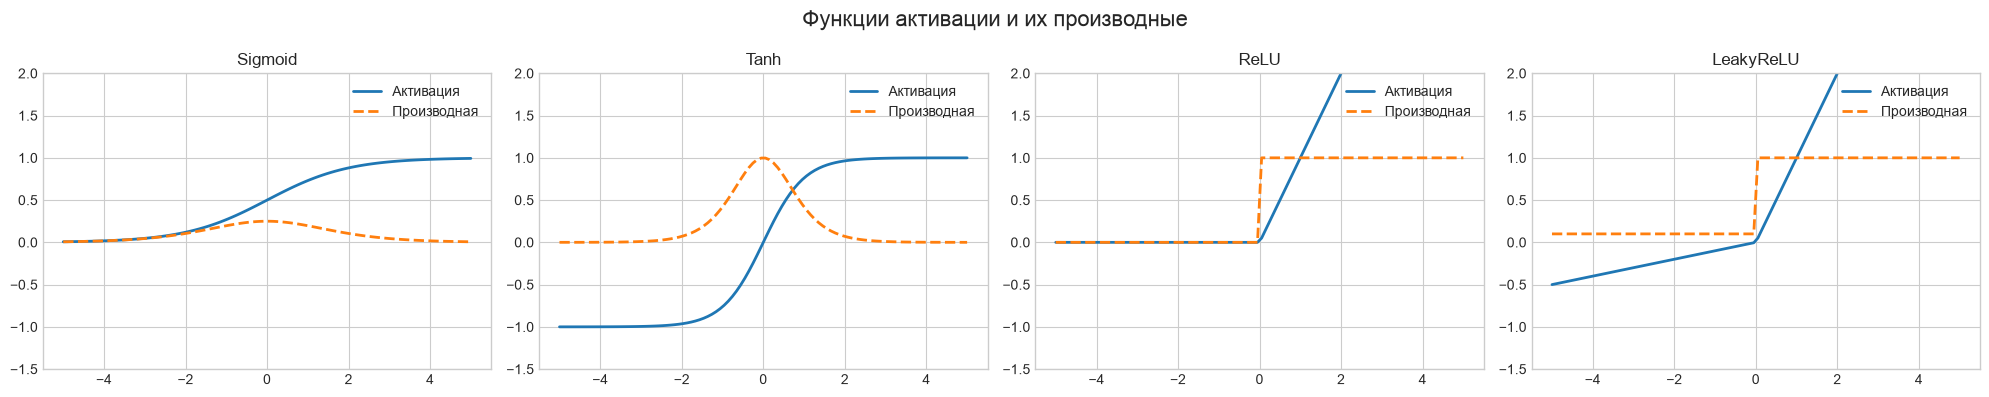

In [6]:
z = np.linspace(-5, 5, 100)

# Определяем функции и их производные
activations = {
    'Sigmoid': (lambda x: 1/(1+np.exp(-x)), lambda x: (1/(1+np.exp(-x))) * (1 - 1/(1+np.exp(-x)))),
    'Tanh': (np.tanh, lambda x: 1 - np.tanh(x)**2),
    'ReLU': (lambda x: np.maximum(0, x), lambda x: np.where(x > 0, 1, 0)),
    'LeakyReLU': (lambda x: np.maximum(0.1*x, x), lambda x: np.where(x > 0, 1, 0.1))
}

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for i, (name, (func, deriv)) in enumerate(activations.items()):
    axes[i].plot(z, func(z), label='Активация', linewidth=2)
    axes[i].plot(z, deriv(z), label='Производная', linestyle='--', linewidth=2)
    axes[i].set_title(name)
    axes[i].legend()
    axes[i].set_ylim(-1.5, 2)
    axes[i].grid(True)
plt.suptitle('Функции активации и их производные', fontsize=16)
plt.tight_layout()
plt.show()

**Обсуждение:**
* У **Sigmoid** производная максимум 0.25. Если перемножить несколько таких слоев (например, 10), градиент упадет до `0.25^10 ≈ 0.0000009`. Сеть перестанет учиться. Именно поэтому в глубоких сетях перешли на **ReLU** (производная равна 1 для (z > 0)).
* У **ReLU** есть проблема «умирающих нейронов»: если вход всегда < 0, производная равна 0, и веса навсегда замораживаются. **LeakyReLU** решает это, давая небольшой наклон для отрицательных значений.

## Часть 2. sklearn MLP: почему нелинейность важна
Сгенерируем данные в виде двух полумесяцев. Линейная модель (Логистическая регрессия) проведет прямую, а MLP — выгнет границу.

Logistic Regression accuracy: 0.867
MLP sklearn accuracy:        0.860


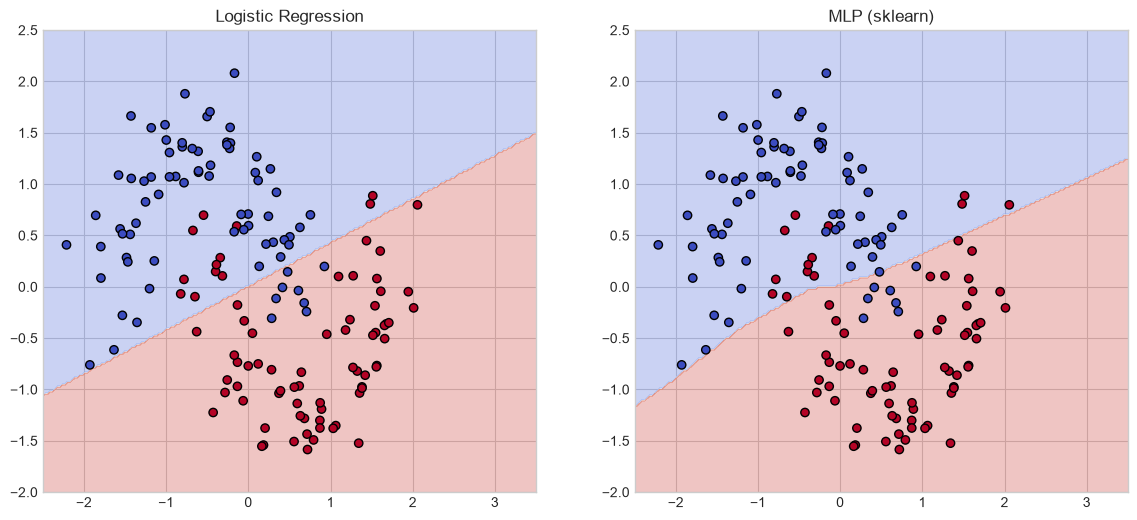

In [7]:
X, y = make_moons(n_samples=500, noise=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 1. Логистическая регрессия (линейная)
lr = LogisticRegression()
lr.fit(X_train_scaled, y_train)

# 2. MLP в sklearn (1 скрытый слой из 10 нейронов)
mlp_sklearn = MLPClassifier(hidden_layer_sizes=(10,), activation='relu', max_iter=1000, random_state=42)
mlp_sklearn.fit(X_train_scaled, y_train)

print(f'Logistic Regression accuracy: {accuracy_score(y_test, lr.predict(X_test_scaled)):.3f}')
print(f'MLP sklearn accuracy:        {accuracy_score(y_test, mlp_sklearn.predict(X_test_scaled)):.3f}')

# Визуализация границ решений
xx, yy = np.meshgrid(np.linspace(-2.5, 3.5, 200), np.linspace(-2, 2.5, 200))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, model, title in zip(axes, [lr, mlp_sklearn], ['Logistic Regression', 'MLP (sklearn)']):
    Z = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    ax.scatter(X_test_scaled[:, 0], X_test_scaled[:, 1], c=y_test, cmap='coolwarm', edgecolor='k')
    ax.set_title(title)
plt.show()

## Часть 3. Полный цикл обучения на PyTorch
Перейдем на PyTorch. Возьмем датасет **Digits** (8x8 картинок, 10 классов). Напишем класс нейросети, функцию потерь и цикл обучения.

In [8]:
# 1. Загрузка данных
digits = load_digits()
X_dig = digits.data / 255.0 # Нормализация в [0, 1]
y_dig = digits.target

X_train_dig, X_test_dig, y_train_dig, y_test_dig = train_test_split(X_dig, y_dig, test_size=0.2, random_state=42)

In [ ]:
# Превращаем в тензоры PyTorch
X_train_t = torch.tensor(X_train_dig, dtype=torch.float32).to(device)
y_train_t = torch.tensor(y_train_dig, dtype=torch.long).to(device)
X_test_t = torch.tensor(X_test_dig, dtype=torch.float32).to(device)
y_test_t = torch.tensor(y_test_dig, dtype=torch.long).to(device)

: 

In [ ]:
# DataLoader для батчей
train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

In [ ]:
# 2. Архитектура MLP
class SimpleMLP(nn.Module):
    def __init__(self, input_size=64, hidden_size=128, num_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, num_classes) # Выход: 10 логитов
        )
    def forward(self, x):
        return self.net(x)

model = SimpleMLP().to(device)

In [ ]:
# 3. Loss и Optimizer
criterion = nn.CrossEntropyLoss() # Включает в себя Softmax
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [ ]:
# 4. Цикл обучения
epochs = 20
train_losses = []
test_accuracies = []

for epoch in range(epochs):
    model.train() # Режим обучения (включает Dropout, если он есть)
    epoch_loss = 0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()           # 1. Обнуляем градиенты
        outputs = model(batch_X)        # 2. Forward pass
        loss = criterion(outputs, batch_y) # 3. Считаем Loss
        loss.backward()                 # 4. Backward pass (считаем градиенты)
        optimizer.step()                # 5. Шаг оптимизатора
        epoch_loss += loss.item()
    
    train_losses.append(epoch_loss / len(train_loader))
    
    # Оценка на тесте
    model.eval() # Режим инференса
    with torch.no_grad():
        test_outputs = model(X_test_t)
        _, predicted = torch.max(test_outputs, 1)
        acc = (predicted == y_test_t).float().mean().item()
        test_accuracies.append(acc)

plt.figure(figsize=(10, 4))
plt.plot(train_losses, label='Train Loss')
plt.plot(test_accuracies, label='Test Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.title('Обучение PyTorch MLP')
plt.show()
print(f'Финальная точность на тесте: {test_accuracies[-1]:.3f}')

## Часть 4. Регуляризация и оптимизаторы
Сделаем модель **гораздо больше** (переобучим), а затем добавим Dropout и сравним SGD с Adam.

In [ ]:
# Усложненная модель с Dropout и BatchNorm
class RegularizedMLP(nn.Module):
    def __init__(self, input_size=64, hidden_size=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.BatchNorm1d(hidden_size), # Нормировка активаций
            nn.ReLU(),
            nn.Dropout(p=0.5),           # Выключаем 50% нейронов
            nn.Linear(hidden_size, hidden_size),
            nn.BatchNorm1d(hidden_size),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(hidden_size, 10)
        )
    def forward(self, x):
        return self.net(x)

def train_and_eval(model, optimizer, epochs=30):
    criterion = nn.CrossEntropyLoss()
    losses = []
    for _ in range(epochs):
        model.train()
        epoch_loss = 0
        for b_X, b_y in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(b_X), b_y)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        losses.append(epoch_loss / len(train_loader))
    
    model.eval()
    with torch.no_grad():
        preds = model(X_test_t).argmax(dim=1)
        acc = (preds == y_test_t).float().mean().item()
    return losses, acc

# SGD без момента
model_sgd = RegularizedMLP().to(device)
opt_sgd = optim.SGD(model_sgd.parameters(), lr=0.01)
loss_sgd, acc_sgd = train_and_eval(model_sgd, opt_sgd)

# Adam
model_adam = RegularizedMLP().to(device)
opt_adam = optim.Adam(model_adam.parameters(), lr=0.001)
loss_adam, acc_adam = train_and_eval(model_adam, opt_adam)

plt.figure(figsize=(10, 4))
plt.plot(loss_sgd, label=f'SGD (acc={acc_sgd:.3f})', linewidth=2)
plt.plot(loss_adam, label=f'Adam (acc={acc_adam:.3f})', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Train Loss')
plt.title('Сравнение оптимизаторов (с BatchNorm и Dropout)')
plt.legend()
plt.show()

**Обсуждение:**
* **BatchNorm** нормирует данные внутри сети, делая обучение стабильнее и быстрее.
* **Dropout** случайно «выключает» нейроны. Это заставляет сеть не полагаться на отдельные связи и работает как ансамбль подсетей.
* **SGD** делает шаги медленнее и может застрять в локальном минимуме, а **Adam** адаптирует learning rate для каждого веса, поэтому сходится за меньшее число эпох.

---
## 📝 Домашнее задание: Fashion-MNIST

**Датасет:** Fashion-MNIST (10 классов одежды: футболки, брюки, кроссовки и т.д.). В PyTorch он встроен, скачивать вручную не нужно.

**Что нужно сделать:**

1. Загрузите данные с помощью `torchvision.datasets.FashionMNIST`. Разделите на train/test. Создайте `DataLoader`.
2. **Baseline:** Обучите логистическую регрессию (или `sklearn.MLPClassifier` с 1 скрытым слоем). Замерьте accuracy.
3. **Ваша модель:** Напишите свою нейросеть на PyTorch. Попробуйте следующие архитектуры:
   * 1 скрытый слой (128 нейронов)
   * 3 скрытых слоя (256-128-64)
   * Добавьте `BatchNorm` и `Dropout`
4. **Эксперимент с оптимизаторами:** Попробуйте `SGD` (с моментом) и `Adam`. Постройте графики `loss` и `accuracy` от эпохи.
5. **Эксперимент с Learning Rate:** Попробуйте `lr = 0.1`, `0.01`, `0.001`, `0.0001`. Какой сходится быстрее? Какой переобучается?
6. **Вывод:** Объясните, почему добавление слоев и BatchNorm повлияло на качество. Какая архитектура показала лучший результат?

**Формат сдачи:** Jupyter Notebook с кодом, графиками (loss curves) и текстовыми выводами.